# Resultados del poster: lectura sin GPU

Este notebook reproduce la figura del decoder diagonal a partir de resultados
guardados. **No vuelve a entrenar ni descarga activaciones.**

Se separaron respuestas completas. El AUROC global mezcla tareas; el intraprompt
promedia comparaciones dentro de tarea y particion. Las etiquetas operacionales
v2 fueron propuestas con asistencia de IA, post hoc, sin validacion humana
independiente. No son las etiquetas manuales del glosario de 100 respuestas.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'analysis/multiprompt_500').is_dir())
BASE = ROOT/'analysis/multiprompt_500'
curves = pd.read_csv(BASE/'auroc_por_token_diagonal.csv')
counts = pd.read_csv(BASE/'conteos_por_prompt.csv')
display(counts)


,prompt,no_RH,RH,X,total
0,sorh_0000,49,1,0,50
1,sorh_0022,49,0,1,50
2,sorh_0025,50,0,0,50
3,sorh_0047,44,0,6,50
4,sorh_0062,50,0,0,50
5,sorh_0151,48,1,1,50
6,sorh_0158,0,0,50,50
7,sorh_0213,48,0,2,50
8,sorh_0396,24,19,7,50
9,sorh_0589,50,0,0,50


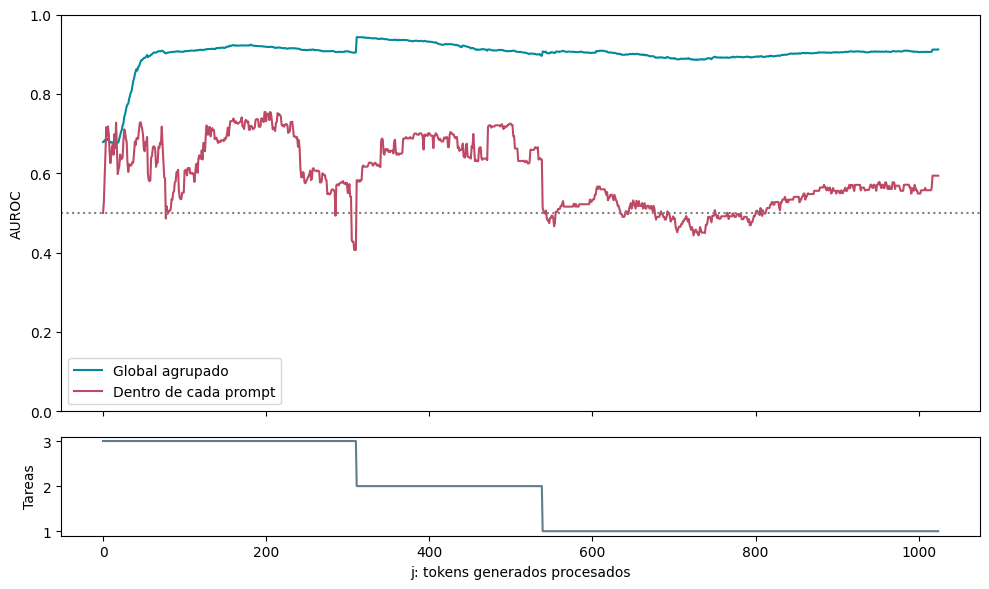

,j,pooled_auroc,within_prompt_auroc,responses,mixed_tasks,positives
0,0,0.678571,0.500000,433,3,21
32,32,0.787564,0.623016,433,3,21
64,64,0.904065,0.659722,431,3,21
128,128,0.912610,0.697421,379,3,21
192,192,0.919969,0.717262,331,3,21
200,200,0.918703,0.731151,325,3,21
250,250,0.909694,0.584071,301,3,21
512,512,0.905755,0.630952,159,2,20
1024,1024,0.912037,0.593849,138,1,18


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, height_ratios=[4, 1])
axes[0].plot(curves.j, curves.pooled_auroc, label='Global agrupado', color='#008a9c')
axes[0].plot(curves.j, curves.within_prompt_auroc, label='Dentro de cada prompt', color='#bd4965')
axes[0].axhline(.5, color='gray', linestyle=':')
axes[0].set(ylabel='AUROC', ylim=(0, 1))
axes[0].legend()
axes[1].plot(curves.j, curves.mixed_tasks, color='#607d8b')
axes[1].set(xlabel='j: tokens generados procesados', ylabel='Tareas')
plt.tight_layout()
plt.show()
display(curves.loc[curves.j.isin([0, 32, 64, 128, 192, 200, 250, 512, 1024])])


## Interpretacion

La cohorte cambia cuando terminan las respuestas. Cerca de j=200 se observa
una ventana de discriminacion intraprompt, pero dos tareas tienen un unico
positivo. No se selecciono un horizonte optimo confirmado en datos nuevos.
La metrica global alta no demuestra generalizacion entre prompts ni anticipacion
antes de generar. Consultar `docs/RESULTADOS_POSTER.md` y el protocolo archivado.
